In [1]:
import osgeo
import rasterio
import rasterio.plot
import rioxarray
import xarray
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from rasterio.windows import Window
from matplotlib import pyplot
import numpy as np
import matplotlib.patches as mpatches
import pandas as pd
import geopandas as gpd
import os
from matplotlib import pyplot
import rasterio.features as features

In [22]:
path_LC_Hansen = 'C:/Users/minttu/Documents/LC_300m_data/ESACCI-LC-L4-LCCS-Map-300m-P1Y-2000-Resample_0.05deg.tif'

In [23]:
path_tree_cover = 'C:/Users/minttu/Documents/Tree_cover/TCD2010_0.05deg.tif'

In [24]:
path_biomes = 'C:/Users/minttu/Documents/Biomes/Resolve_Ecoregions/Biomes_and_Ecoregions_2017.shp'

In [25]:
LCHansen2000 = rioxarray.open_rasterio(path_LC_Hansen)

In [36]:
with rasterio.open(path_LC_Hansen) as src:
    transform = src.transform
    shape = src.shape

In [26]:
Tree_cover = rioxarray.open_rasterio(path_tree_cover)

In [7]:
Biomes = gpd.read_file(path_biomes)

C:\Users\minttu\anaconda3\envs\rasterio_env\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: C:/Users/minttu/Documents/Biomes/Resolve_Ecoregions/Biomes_and_Ecoregions_2017.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


In [77]:
LCHansen2000

<xarray.DataArray (band: 1, y: 3600, x: 7200)> Size: 104MB
array([[[210., 210., ..., 210., 210.],
        [210., 210., ..., 210., 210.],
        ...,
        [220., 220., ..., 220., 220.],
        [220., 220., ..., 220., 220.]]], shape=(1, 3600, 7200), dtype=float32)
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 29kB 89.97 89.92 89.88 ... -89.88 -89.93 -89.98
  * x            (x) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [8]:
print(Biomes.crs)

EPSG:4326


In [13]:
print(Biomes.info())

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 847 entries, 0 to 846
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID_1  847 non-null    float64 
 1   ECO_NAME    847 non-null    str     
 2   BIOME_NUM   847 non-null    float64 
 3   BIOME_NAME  847 non-null    str     
 4   REALM       847 non-null    str     
 5   ECO_BIOME_  847 non-null    str     
 6   NNH         847 non-null    float64 
 7   ECO_ID      847 non-null    float64 
 8   SHAPE_LENG  847 non-null    float64 
 9   NNH_NAME    847 non-null    str     
 10  COLOR       847 non-null    str     
 11  COLOR_BIO   847 non-null    str     
 12  COLOR_NNH   847 non-null    str     
 13  LICENSE     847 non-null    str     
 14  geometry    847 non-null    geometry
dtypes: float64(5), geometry(1), str(9)
memory usage: 99.4 KB
None


In [14]:
print(Biomes["BIOME_NAME"].unique())

<StringArray>
[                                                  'Tundra',
           'Tropical & Subtropical Moist Broadleaf Forests',
                 'Mediterranean Forests, Woodlands & Scrub',
                               'Deserts & Xeric Shrublands',
              'Temperate Grasslands, Savannas & Shrublands',
                                     'Boreal Forests/Taiga',
                                'Temperate Conifer Forests',
                      'Temperate Broadleaf & Mixed Forests',
                          'Montane Grasslands & Shrublands',
                                                'Mangroves',
                            'Flooded Grasslands & Savannas',
 'Tropical & Subtropical Grasslands, Savannas & Shrublands',
             'Tropical & Subtropical Dry Broadleaf Forests',
                'Tropical & Subtropical Coniferous Forests',
                                                      'N/A']
Length: 15, dtype: str


# Define biomes

Nature article: 14 biomes defined by Nature conservancy:

Tropical moist
Tropical dry
Temperate broadleaf
Temperate coniferous
Boreal
Tropical grasslands
Temperate grasslands
Flooded grasslands
Montane grasslands
Tundra
Mediterranean forest
Deserts
Mangroves

divide boreal into classes (latitude, altitude), sharper histograms, broadleaf, evergreen

Tree cover, needle leaved, evergreen, closed to open (>15%) 70
Tree cover, needle leaved, evergreen, closed (>40%) 71
Tree cover, needle leaved, evergreen, open (15 – 40%) 72

In [ ]:
LCHansen2000tree = (LCHansen2000 < 210)

In [48]:
LCHansen2000boreal = (LCHansen2000 >= 50) & (LCHansen2000 <= 110) | (LCHansen2000 >= 160) & (LCHansen2000 <= 170)

Sparse vegetation (tree, shrub, herbaceous cover) (<15%) 150


In [15]:
LCHansen2000desert = (LCHansen2000 == 150)

Shrub or herbaceous cover, flooded, fresh/saline/brackish
water 180

In [16]:
LCHansen2000flooded_grassland = (LCHansen2000 == 180)

## Biomes

In [66]:
boreal = Biomes[Biomes["BIOME_NAME"] == "Boreal Forests/Taiga"]

In [67]:
desert = Biomes[Biomes["BIOME_NAME"] == "Deserts & Xeric Shrublands"]

In [68]:
temperate_broadleaf = Biomes[Biomes["BIOME_NAME"] == "Temperate Broadleaf & Mixed Forests"]

In [69]:
temperate_coniferous = Biomes[Biomes["BIOME_NAME"] == "Temperate Conifer Forests"]

In [70]:
tundra = Biomes[Biomes["BIOME_NAME"] == "Tundra"]

In [71]:
temperate_grasslands = Biomes[Biomes["BIOME_NAME"] == "Temperate Grasslands, Savannas & Shrublands"]

In [72]:
montane_grasslands = Biomes[Biomes["BIOME_NAME"] == "Montane Grasslands & Shrublands"]

# Plot Tree cover and biomes

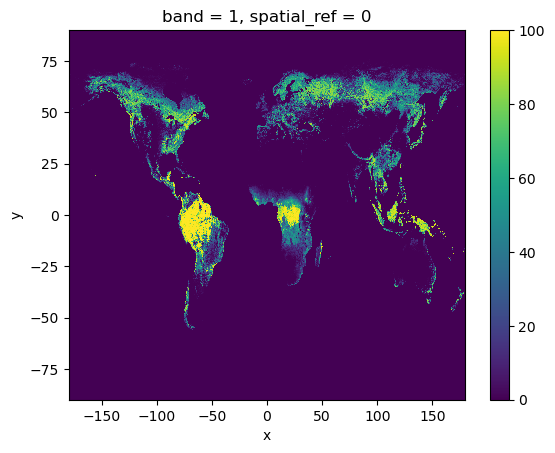

In [16]:
Tree_cover.plot()

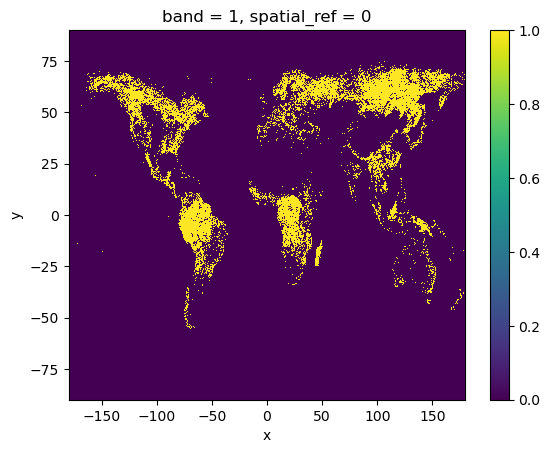

In [49]:
LCHansen2000boreal.plot()

In [9]:
Biomes = Biomes.to_crs(epsg=3857)  # meters
Biomes["geometry"] = Biomes["geometry"].simplify(1000)  # 1 km tolerance
Biomes = Biomes.to_crs(epsg=4326)

C:\Users\minttu\AppData\Local\Temp\ipykernel_5300\1735932783.py:19: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = pyplot.cm.get_cmap("tab20", len(categories))


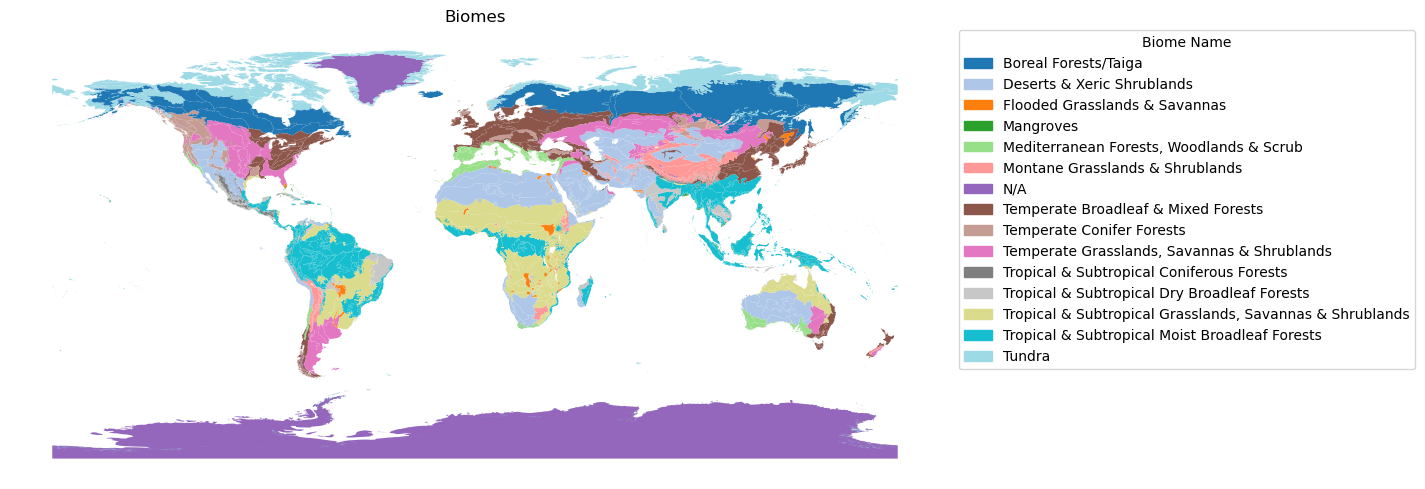

In [65]:
fig, ax = pyplot.subplots(figsize=(12, 8))

# plot with categorical coloring
plot = Biomes.plot(
    column="BIOME_NAME",
    categorical=True,
    legend=False,
    cmap="tab20",
    ax=ax
)

ax.set_title("Biomes")
ax.set_axis_off()

# extract the same categories in the same order GeoPandas uses
categories = Biomes["BIOME_NAME"].astype("category").cat.categories

# get the colormap used
cmap = pyplot.cm.get_cmap("tab20", len(categories))

# build legend that matches plotting order/colors
patches = [
    mpatches.Patch(color=cmap(i), label=cat)
    for i, cat in enumerate(categories)
]

ax.legend(
    handles=patches,
    title="Biome Name",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0
)

pyplot.show()

Text(0.5, 1.0, 'Boreal Biome')

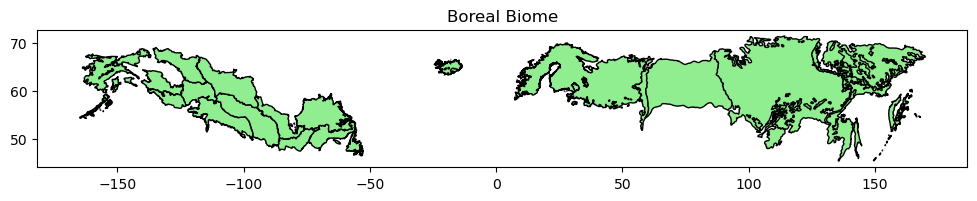

In [19]:
boreal.plot(
    figsize=(12, 8),
    color="lightgreen",
    edgecolor="black"
)

pyplot.title("Boreal Biome")

# Calculate tree density for different biomes

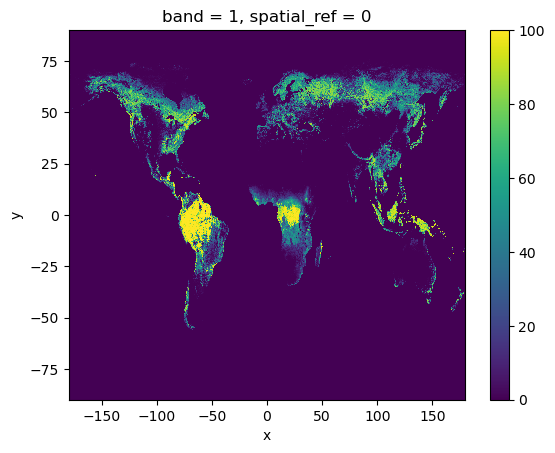

In [78]:
Tree_cover.plot()

In [84]:
mask_boreal = features.rasterize(
    [(geom, 1) for geom in boreal.geometry],
    out_shape=Tree_density.shape[-2:],
    transform=transform,   # from raster
    fill=0
)

In [92]:
mask_desert = features.rasterize(
    [(geom, 1) for geom in desert.geometry],
    out_shape=Tree_density.shape[-2:],
    transform=transform,   # from raster
    fill=0
)

In [93]:
mask_temperate_broadleaf = features.rasterize(
    [(geom, 1) for geom in temperate_broadleaf.geometry],
    out_shape=Tree_density.shape[-2:],
    transform=transform,   # from raster
    fill=0
)

In [94]:
mask_temperate_coniferous = features.rasterize(
    [(geom, 1) for geom in temperate_coniferous.geometry],
    out_shape=Tree_density.shape[-2:],
    transform=transform,   # from raster
    fill=0
)

In [95]:
mask_tundra = features.rasterize(
    [(geom, 1) for geom in tundra.geometry],
    out_shape=Tree_density.shape[-2:],
    transform=transform,   # from raster
    fill=0
)

In [96]:
mask_temperate_grasslands = features.rasterize(
    [(geom, 1) for geom in temperate_grasslands.geometry],
    out_shape=Tree_density.shape[-2:],
    transform=transform,   # from raster
    fill=0
)

In [98]:
mask_montane_grasslands = features.rasterize(
    [(geom, 1) for geom in montane_grasslands.geometry],
    out_shape=Tree_density.shape[-2:],
    transform=transform,   # from raster
    fill=0
)

In [148]:
mask_boreal_arr = mask_boreal.astype(bool)

In [166]:
mask_desert_arr = mask_desert.astype(bool)

In [167]:
mask_temperate_broadleaf_arr = mask_temperate_broadleaf.astype(bool)

In [168]:
mask_temperate_coniferous_arr = mask_temperate_coniferous.astype(bool)

In [169]:
mask_tundra_arr = mask_tundra.astype(bool)

In [170]:
mask_temperate_grasslands_arr = mask_temperate_grasslands.astype(bool)

In [171]:
mask_montane_grasslands_arr = mask_montane_grasslands.astype(bool)

In [209]:
borealTree_density_biome = Tree_cover.where(mask_boreal_arr)

In [210]:
borealTree_density_biome = Tree_cover.where(mask_boreal_arr)

In [211]:
desertTree_density_biome = Tree_cover.where(mask_desert_arr)

In [212]:
temperate_broadleafTree_density_biome = Tree_cover.where(mask_temperate_broadleaf_arr)

In [213]:
temperate_coniferousTree_density_biome = Tree_cover.where(mask_temperate_coniferous_arr)

In [214]:
tundra_Tree_density_biome = Tree_cover.where(mask_tundra_arr)

In [215]:
temperate_grasslandsTree_density_biome = Tree_cover.where(mask_temperate_grasslands_arr)

In [216]:
montane_grasslandsTree_density_biome = Tree_cover.where(mask_montane_grasslands_arr)

# Plot tree densities for biomes

Text(0.5, 1.0, 'Boreal biome tree density')

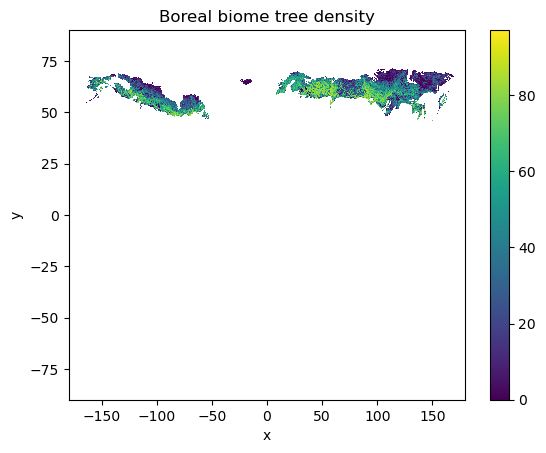

In [165]:
borealTree_density_biome.plot()
pyplot.title("Boreal biome tree density")

Text(0.5, 1.0, 'Desert biome tree density')

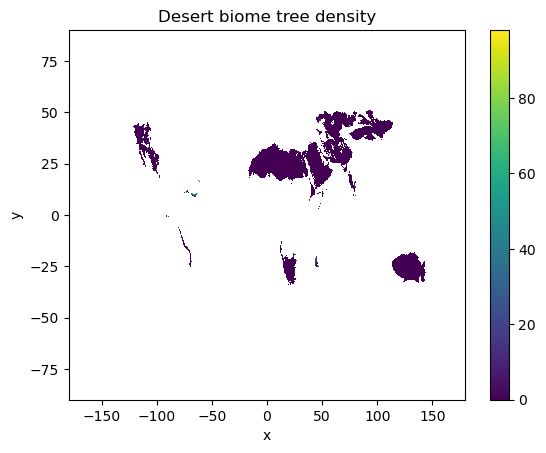

In [179]:
desertTree_density_biome.plot()
pyplot.title("Desert biome tree density")

Text(0.5, 1.0, 'Temperate broadleaf biome tree density')

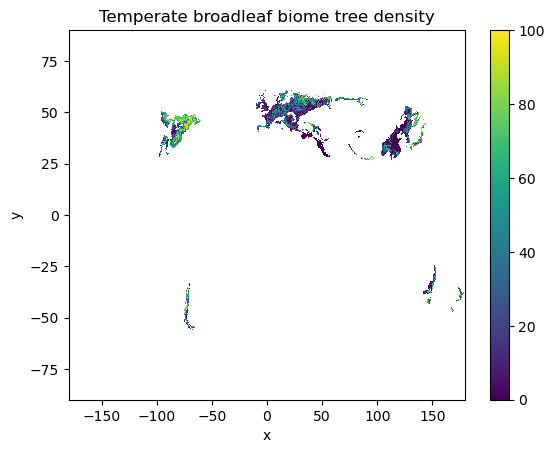

In [180]:
temperate_broadleafTree_density_biome.plot()
pyplot.title("Temperate broadleaf biome tree density")

Text(0.5, 1.0, 'Temperate coniferous biome tree density')

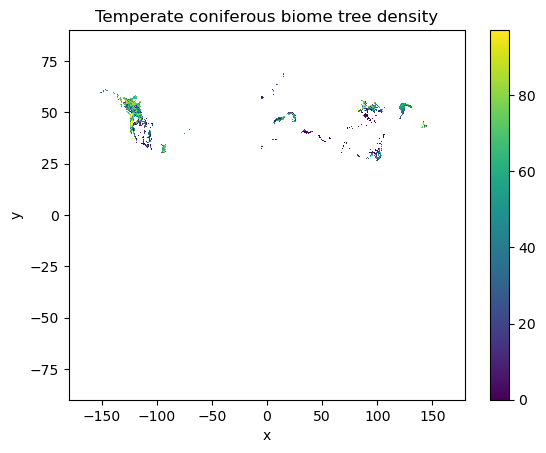

In [181]:
temperate_coniferousTree_density_biome.plot()
pyplot.title("Temperate coniferous biome tree density")

Text(0.5, 1.0, 'Tundra biome tree density')

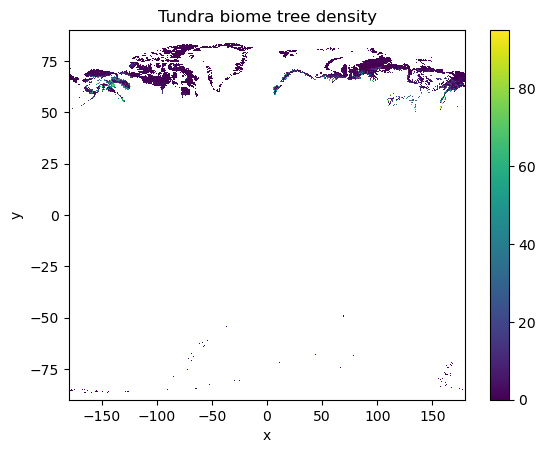

In [182]:
tundra_Tree_density_biome.plot()
pyplot.title("Tundra biome tree density")

Text(0.5, 1.0, 'Temperate grasslands biome tree density')

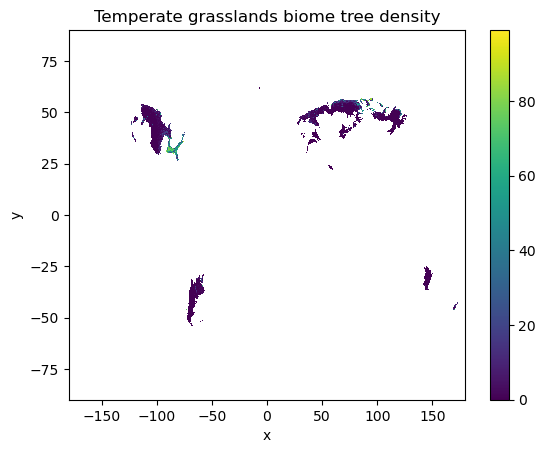

In [183]:
temperate_grasslandsTree_density_biome.plot()
pyplot.title("Temperate grasslands biome tree density")

Text(0.5, 1.0, 'Montane grasslands biome tree density')

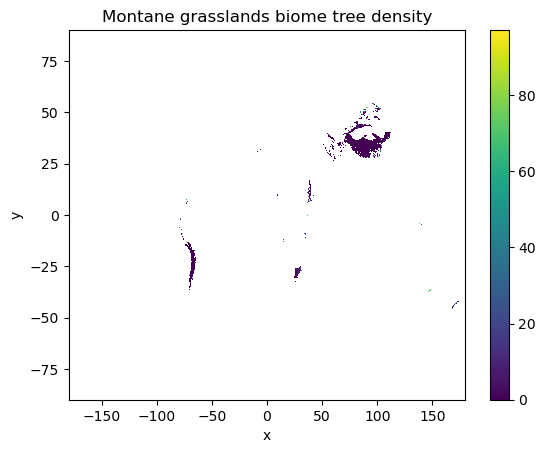

In [184]:
montane_grasslandsTree_density_biome.plot()
pyplot.title("Montane grasslands biome tree density")

# Plot histograms

In [217]:
borealTree_density_biomecleaned = borealTree_density_biome.where(borealTree_density_biome != 0)

In [218]:
desertTree_density_biomecleaned = desertTree_density_biome.where(desertTree_density_biome != 0)

In [219]:
temperate_broadleafTree_density_biomecleaned = borealTree_density_biome.where(temperate_broadleafTree_density_biome != 0)

In [220]:
temperate_coniferousTree_density_biomecleaned = borealTree_density_biome.where(temperate_coniferousTree_density_biome != 0)

In [221]:
tundra_Tree_density_biomecleaned = borealTree_density_biome.where(tundra_Tree_density_biome != 0)

In [229]:
temperate_grasslandsTree_density_biomecleaned = temperate_grasslandsTree_density_biome.where(temperate_grasslandsTree_density_biome != 0)

In [230]:
montane_grasslandsTree_density_biomecleaned = montane_grasslandsTree_density_biome.where(montane_grasslandsTree_density_biome != 0)

Text(0.5, 1.0, 'LC Hansen Boreal biome density')

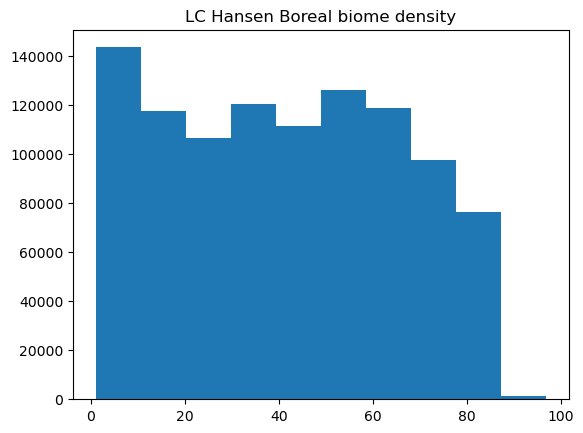

In [222]:
xarray.plot.hist(borealTree_density_biomecleaned)
pyplot.title("LC Hansen Boreal biome density")

Text(0.5, 1.0, 'LC Hansen desert tree density')

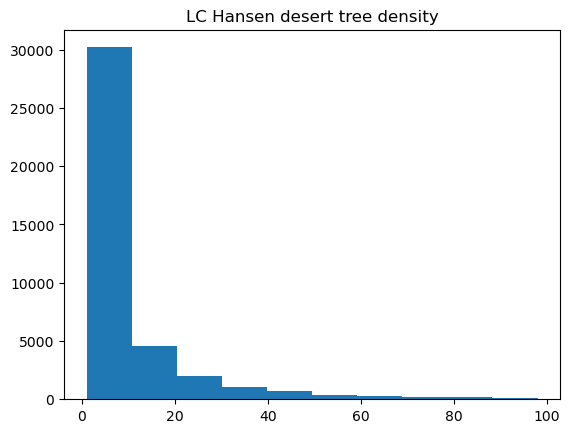

In [223]:
xarray.plot.hist(desertTree_density_biomecleaned)
pyplot.title("LC Hansen desert tree density")

Text(0.5, 1.0, 'LC Hansen temperate broadleaf tree density')

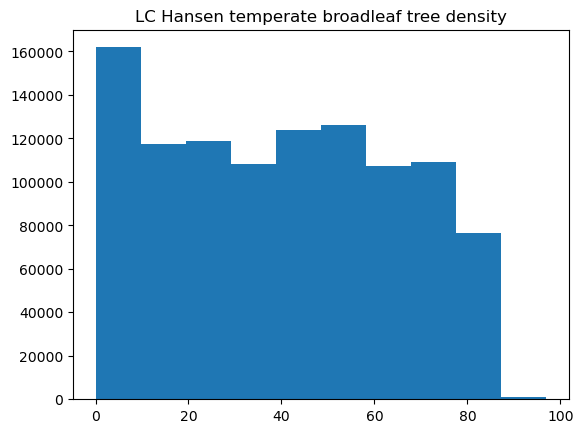

In [224]:
xarray.plot.hist(temperate_broadleafTree_density_biomecleaned)
pyplot.title("LC Hansen temperate broadleaf tree density")

Text(0.5, 1.0, 'LC Hansen temperate coniferous tree density')

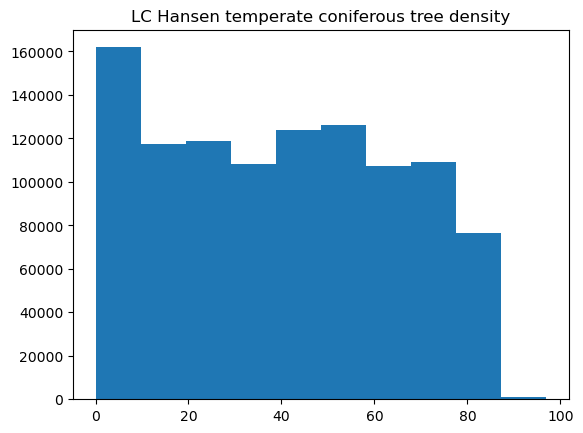

In [225]:
xarray.plot.hist(temperate_coniferousTree_density_biomecleaned)
pyplot.title("LC Hansen temperate coniferous tree density")

Text(0.5, 1.0, 'LC Hansen tundra biome density')

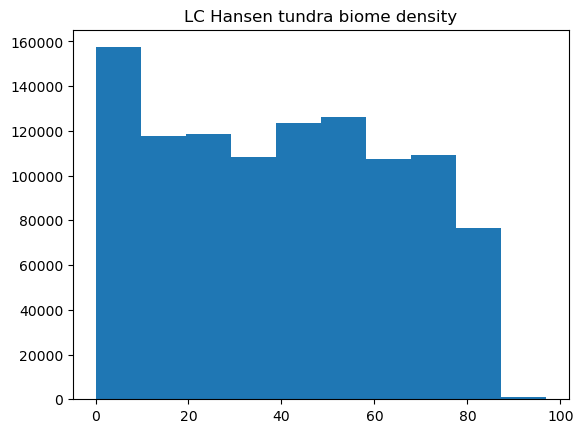

In [226]:
xarray.plot.hist(tundra_Tree_density_biomecleaned)
pyplot.title("LC Hansen tundra biome density")

Text(0.5, 1.0, 'LC Hansen temperate grasslands tree density')

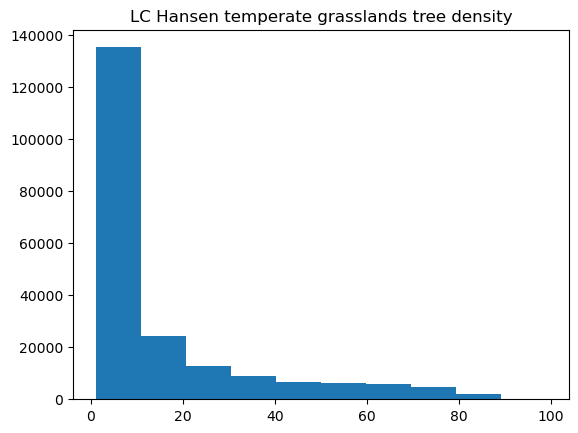

In [231]:
xarray.plot.hist(temperate_grasslandsTree_densitycleaned)
pyplot.title("LC Hansen temperate grasslands tree density")

Text(0.5, 1.0, 'LC Hansen montane grasslands tree density')

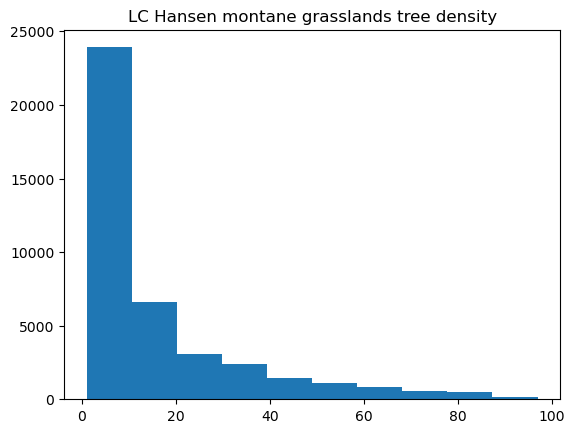

In [232]:
xarray.plot.hist(montane_grasslandsTree_densitycleaned)
pyplot.title("LC Hansen montane grasslands tree density")